# Etapa 2 — Transformação: Painéis Multi-Indicador

Transforma os dados brutos em **cinco painéis tidy** — um por indicador — prontos para a avaliação de qualidade (Etapa 3) e para a alternativa probabilística (Etapa 5). Cada linha é uma combinação `(período/reunião alvo, horizonte)`.

## A ideia central: `data_travamento`

Para cada período de referência `P` e horizonte `h`, o **consenso Focus é lido na última pesquisa publicada dentro do mês `P − h`**. Essa data — `data_travamento` — é o instante em que **toda** feature precisa ser avaliada. Nenhuma feature pode usar informação publicada depois dela.

Como a base Focus já registra `(data_pesquisa, referencia)`, o horizonte `h` não precisa de calendário auxiliar: é a diferença em meses entre o alvo e o mês da pesquisa. Selecionar "a última pesquisa do mês `P−h`" vira um `groupby` + `idxmax` — a construção do alvo já nasce *point-in-time* por definição.

## Por que quatro indicadores compartilham o mesmo código

IPCA, Câmbio, IGP-M e Taxa de desocupação têm **exatamente a mesma forma** no OData (mensais, chaveados por `DataReferencia`), então uma única função constrói os quatro painéis. A **Selic** é o caso à parte: chaveada por reunião do Copom, não por mês.

## Alvo

$$\text{ErroFocus}(P, h) = \text{Realizado}(P) - \text{Mediana}_{\text{Focus}}(P, h)$$

Convenção de sinal: **erro positivo = o Focus subestimou** (o realizado veio acima do previsto).

A Selic realizada vem do **calendário do Copom**, não da série SGS 432 — evitando a armadilha da vigência prospectiva. O Câmbio realizado usa a **média mensal** (SGS 3698), decisão tomada empiricamente na Etapa 1.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import (
    DIR_BRUTO, DIR_REFERENCIA, DIR_PROCESSADO, HORIZONTES_MESES, INDICADORES_MENSAIS, SERIES_SGS,
)
from focus.armazenamento import carregar_dataset, salvar_dataset
from focus.pontual import calcular_data_disponibilidade, juntar_as_of
from focus.benchmark import previsao_ingenua_mensal, previsao_ingenua_selic

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Focus, por indicador -------------------------------------------------
focus_mensal, focus_top5_mensal = {}, {}
for indicador, cfg in INDICADORES_MENSAIS.items():
    nome = cfg["nome"]
    focus_mensal[nome] = carregar_dataset(DIR_BRUTO, f"focus_{nome}_mensal")
    focus_top5_mensal[nome] = carregar_dataset(DIR_BRUTO, f"focus_{nome}_top5_mensal")

focus_selic = carregar_dataset(DIR_BRUTO, "focus_selic")
focus_top5_selic = carregar_dataset(DIR_BRUTO, "focus_top5_selic")
calendario_copom = carregar_dataset(DIR_REFERENCIA, "calendario_copom")

# --- Realizados (SGS) -----------------------------------------------------
# O nome do dataset persistido vem de SERIES_SGS (fonte unica da convencao):
# o do IPCA, por exemplo, e "sgs_ipca_mensal", nao "sgs_ipca".
realizados = {cfg["nome"]: carregar_dataset(DIR_BRUTO, f"sgs_{SERIES_SGS[cfg['sgs']][0]}")
              for cfg in INDICADORES_MENSAIS.values()}

# --- Features macro compartilhadas por TODOS os paineis -------------------
sgs_ipca_mensal = carregar_dataset(DIR_BRUTO, "sgs_ipca_mensal")
sgs_meta_selic = carregar_dataset(DIR_BRUTO, "sgs_meta_selic")
sgs_ibcbr = carregar_dataset(DIR_BRUTO, "sgs_ibcbr")
sgs_icbr = carregar_dataset(DIR_BRUTO, "sgs_icbr")
sgs_meta_inflacao = carregar_dataset(DIR_BRUTO, "sgs_meta_inflacao")
mercado_usdbrl = carregar_dataset(DIR_BRUTO, "mercado_usdbrl")
mercado_tnx = carregar_dataset(DIR_BRUTO, "mercado_tnx")

for nome, df in focus_mensal.items():
    print(f"focus_{nome:<12} {len(df):>8,} linhas | realizado: {len(realizados[nome]):>4} obs")
print(f"focus_selic      {len(focus_selic):>8,} linhas | calendario Copom: {len(calendario_copom)} reunioes")

focus_ipca           99,229 linhas | realizado:  272 obs
focus_cambio         97,801 linhas | realizado:  272 obs
focus_igpm           89,257 linhas | realizado:  272 obs
focus_desocupacao    22,572 linhas | realizado:  173 obs
focus_selic        65,022 linhas | calendario Copom: 166 reunioes


## 1. Construção do alvo — indicadores mensais

`referencia` chega como string `"MM/AAAA"`. Convertendo para timestamp de **primeiro dia do mês**, fica diretamente comparável com a coluna `data` do SGS (que também indexa a observação mensal pelo primeiro dia do mês de referência).

In [2]:
def construir_painel_mensal(nome, focus_df, realizado_df):
    '''Constroi o painel (alvo + consenso) de um indicador mensal qualquer.
    Devolve uma linha por (periodo de referencia, horizonte).'''
    df = focus_df.copy()
    df["referencia_periodo"] = pd.to_datetime(df["referencia"], format="%m/%Y")
    df["horizonte_calendario"] = (
        df["referencia_periodo"].dt.to_period("M") - df["data_pesquisa"].dt.to_period("M")
    ).apply(lambda o: o.n)

    blocos = []
    for h in HORIZONTES_MESES:
        df_h = df.loc[df["horizonte_calendario"] == h]
        # "ultima pesquisa do mes P-h": o grupo ja esta filtrado para o mes certo
        idx_ultima = df_h.groupby("referencia_periodo")["data_pesquisa"].idxmax()
        bloco = df_h.loc[idx_ultima].copy()
        bloco["horizonte"] = h
        blocos.append(bloco)

    painel = pd.concat(blocos, ignore_index=True).rename(columns={
        "data_pesquisa": "data_travamento",
        "media": "media_focus", "mediana": "mediana_focus",
        "desvio_padrao": "desvio_padrao_focus", "minimo": "minimo_focus",
        "maximo": "maximo_focus", "num_respondentes": "num_respondentes_focus",
    })[[
        "referencia_periodo", "horizonte", "data_travamento", "media_focus", "mediana_focus",
        "desvio_padrao_focus", "minimo_focus", "maximo_focus", "num_respondentes_focus",
    ]]

    real = realizado_df.rename(columns={"data": "referencia_periodo", "valor": "realizado"})
    painel = painel.merge(real, on="referencia_periodo", how="left")
    painel["erro_focus"] = painel["realizado"] - painel["mediana_focus"]

    n_sem = int(painel["realizado"].isna().sum())
    painel = painel.dropna(subset=["realizado"]).reset_index(drop=True)
    painel["indicador"] = nome
    return painel, n_sem


paineis = {}
for indicador, cfg in INDICADORES_MENSAIS.items():
    nome = cfg["nome"]
    paineis[nome], n_sem = construir_painel_mensal(nome, focus_mensal[nome], realizados[nome])
    p = paineis[nome]
    print(f"{indicador:<22} {len(p):>4} linhas | {p['referencia_periodo'].min():%Y-%m} -> "
          f"{p['referencia_periodo'].max():%Y-%m} | {n_sem} sem realizado (descartadas)")

IPCA                    970 linhas | 2006-02 -> 2026-08 | 26 sem realizado (descartadas)


Câmbio                  970 linhas | 2006-02 -> 2026-08 | 26 sem realizado (descartadas)


IGP-M                   970 linhas | 2006-02 -> 2026-08 | 26 sem realizado (descartadas)


Taxa de desocupação     214 linhas | 2021-10 -> 2026-07 | 30 sem realizado (descartadas)


## 2. Construção do alvo — Selic (por reunião do Copom)

Mesma lógica, mas a "referência" é `reuniao` (`"R6/2026"`). O horizonte é medido em meses de calendário (bucket `h`) e também em **meses corridos exatos** (`horizonte_m`) — a grade de reuniões é irregular (~45–60 dias), então o bucket é uma aproximação e os modelos devem ver o valor contínuo.

In [3]:
cal = calendario_copom.set_index("rotulo_reuniao")

df = focus_selic.loc[focus_selic["reuniao"].isin(cal.index)].copy()
df["data_reuniao"] = df["reuniao"].map(cal["data_reuniao"])
df["realizado"] = df["reuniao"].map(cal["meta_selic"])
df["horizonte_calendario"] = (
    df["data_reuniao"].dt.to_period("M") - df["data_pesquisa"].dt.to_period("M")
).apply(lambda o: o.n)

blocos = []
for h in HORIZONTES_MESES:
    df_h = df.loc[df["horizonte_calendario"] == h]
    idx_ultima = df_h.groupby("reuniao")["data_pesquisa"].idxmax()
    bloco = df_h.loc[idx_ultima].copy()
    bloco["horizonte"] = h
    blocos.append(bloco)

painel_selic = pd.concat(blocos, ignore_index=True).rename(columns={
    "data_pesquisa": "data_travamento",
    "media": "media_focus", "mediana": "mediana_focus",
    "desvio_padrao": "desvio_padrao_focus", "minimo": "minimo_focus",
    "maximo": "maximo_focus", "num_respondentes": "num_respondentes_focus",
})

painel_selic["horizonte_m"] = (
    (painel_selic["data_reuniao"] - painel_selic["data_travamento"]).dt.days / 30.4375
).round(2)
painel_selic["erro_focus"] = painel_selic["realizado"] - painel_selic["mediana_focus"]
painel_selic["indicador"] = "selic"

# sanidade: a reuniao-alvo tem que ser POSTERIOR a data_travamento
violacoes = painel_selic["data_reuniao"] <= painel_selic["data_travamento"]
assert not violacoes.any(), f"{violacoes.sum()} linha(s) com reuniao-alvo <= data_travamento!"

painel_selic = painel_selic[[
    "reuniao", "horizonte", "horizonte_m", "data_travamento", "data_reuniao", "indicador",
    "media_focus", "mediana_focus", "desvio_padrao_focus", "minimo_focus", "maximo_focus",
    "num_respondentes_focus", "realizado", "erro_focus",
]].sort_values(["data_reuniao", "horizonte"]).reset_index(drop=True)

paineis["selic"] = painel_selic
print(f"Selic  {len(painel_selic):>4} linhas | {painel_selic['data_reuniao'].min():%Y-%m} -> "
      f"{painel_selic['data_reuniao'].max():%Y-%m}")

Selic   648 linhas | 2006-03 -> 2026-09


## 3. Teste de evento conhecido

Checagem de sanidade barata e poderosa: o IPCA de **mar/2021** projetado com `h=12` (pesquisa de mar/2020, pré-COVID) deve ter erro fortemente **positivo** — pela convenção `erro = realizado − mediana`, uma subestimação do consenso produz erro positivo. O realizado veio em 0,93% contra uma mediana de ~0,30%.

In [4]:
evento = paineis["ipca"].loc[
    (paineis["ipca"]["referencia_periodo"] == pd.Timestamp("2021-03-01"))
    & (paineis["ipca"]["horizonte"] == 12)
]
display(evento[["referencia_periodo", "horizonte", "data_travamento", "mediana_focus", "realizado", "erro_focus"]])

assert len(evento) == 1, "linha do evento de teste nao encontrada"
assert evento["erro_focus"].iloc[0] > 0.3, "erro deveria ser fortemente positivo (Focus subestimou)"
print("OK: o consenso de mar/2020 subestimou o IPCA de mar/2021, como esperado.")

,referencia_periodo,horizonte,data_travamento,mediana_focus,realizado,erro_focus
904,2021-03-01,12,2020-03-31,0.3,0.93,0.63


OK: o consenso de mar/2020 subestimou o IPCA de mar/2021, como esperado.


## 4. Features de estrutura do consenso

Vêm da própria linha do painel (já *point-in-time* por construção) ou de um join dentro do próprio Focus — não passam pelo mecanismo de defasagem de publicação.

**Nota sobre `cv_focus` e `assimetria_focus`:** ambas dividem pelo desvio-padrão ou pela mediana, que podem ser zero (poucos respondentes convergindo no mesmo valor). Tratamos `±inf` como ausência de sinal (`NaN`), não como outlier extremo.

**Cobertura do Top 5 não é uniforme entre indicadores.** A ingestão revelou que o Focus **não publica Top 5 para Taxa de desocupação** (zero linhas), e publica cobertura parcial para Câmbio e IGP-M. A feature `spread_top5_mediana` fica `NaN` onde não há Top 5 — sinalizado explicitamente abaixo, para não virar uma coluna silenciosamente vazia que passaria despercebida na modelagem.

In [5]:
def adicionar_dispersao(painel):
    p = painel.copy()
    p["cv_focus"] = p["desvio_padrao_focus"] / p["mediana_focus"].abs()
    p["amplitude_focus"] = p["maximo_focus"] - p["minimo_focus"]
    p["assimetria_focus"] = (p["media_focus"] - p["mediana_focus"]) / p["desvio_padrao_focus"]
    return p.replace({"cv_focus": [np.inf, -np.inf], "assimetria_focus": [np.inf, -np.inf]}, np.nan)


def adicionar_spread_top5(painel, top5, colunas_chave):
    '''Junta a mediana do Top 5 publicada na MESMA data de pesquisa (match
    exato: Top 5 e mediana geral saem juntos no mesmo dia).'''
    slim = top5.rename(columns={"data_pesquisa": "data_travamento", "mediana": "mediana_top5"})
    slim = slim[["data_travamento", *colunas_chave, "mediana_top5"]]
    p = painel.merge(slim, on=["data_travamento", *colunas_chave], how="left")
    p["spread_top5_mediana"] = p["mediana_top5"] - p["mediana_focus"]
    return p


def adicionar_revisao(painel, serie_completa, coluna_chave, dias, nome):
    '''Variacao da mediana para o MESMO alvo entre pesquisas separadas por
    ~`dias`. Testa diretamente a hipotese "Focus e adaptativo".'''
    serie = (serie_completa[[coluna_chave, "data_pesquisa", "mediana"]]
             .rename(columns={"data_pesquisa": "data_alvo", "mediana": f"mediana_{nome}"})
             .sort_values("data_alvo"))

    alvo = painel[[coluna_chave, "data_travamento"]].copy()
    alvo["data_alvo"] = alvo["data_travamento"] - pd.Timedelta(days=dias)
    alvo_ordenado = alvo.sort_values("data_alvo")

    resultado = pd.merge_asof(alvo_ordenado, serie, on="data_alvo",
                              by=coluna_chave, direction="backward")
    # merge_asof descarta o indice: devolvemos os rotulos originais e
    # reordenamos antes de extrair, senao os valores saem desalinhados.
    resultado.index = alvo_ordenado.index
    resultado = resultado.reindex(painel.index)

    p = painel.copy()
    p[f"revisao_focus_{nome}"] = p["mediana_focus"] - resultado[f"mediana_{nome}"]
    return p


for nome in paineis:
    paineis[nome] = adicionar_dispersao(paineis[nome])

# Top 5 + revisao: chave difere entre mensais (referencia_periodo) e Selic (reuniao)
for indicador, cfg in INDICADORES_MENSAIS.items():
    nome = cfg["nome"]
    top5 = focus_top5_mensal[nome].copy()
    top5["referencia_periodo"] = pd.to_datetime(top5["referencia"], format="%m/%Y")
    paineis[nome] = adicionar_spread_top5(paineis[nome], top5, ["referencia_periodo"])

    serie_rev = focus_mensal[nome].assign(
        referencia_periodo=pd.to_datetime(focus_mensal[nome]["referencia"], format="%m/%Y")
    )
    for dias, rot in [(21, "1m"), (63, "3m")]:
        paineis[nome] = adicionar_revisao(paineis[nome], serie_rev, "referencia_periodo", dias, rot)

paineis["selic"] = adicionar_spread_top5(paineis["selic"], focus_top5_selic, ["reuniao"])
for dias, rot in [(21, "1m"), (63, "3m")]:
    paineis["selic"] = adicionar_revisao(paineis["selic"], focus_selic, "reuniao", dias, rot)

for nome, p in paineis.items():
    cob = p["spread_top5_mediana"].notna().mean()
    aviso = "  <- Focus NAO publica Top 5 para este indicador" if cob == 0 else ""
    print(f"{nome:<12} cobertura spread_top5={cob:.3f} | "
          f"revisao_1m={p['revisao_focus_1m'].notna().mean():.3f}{aviso}")

ipca         cobertura spread_top5=1.000 | revisao_1m=1.000
cambio       cobertura spread_top5=0.796 | revisao_1m=1.000
igpm         cobertura spread_top5=0.796 | revisao_1m=1.000
desocupacao  cobertura spread_top5=0.000 | revisao_1m=0.981  <- Focus NAO publica Top 5 para este indicador
selic        cobertura spread_top5=0.998 | revisao_1m=1.000


## 5. Flags de regime do Copom

Construídas uma vez sobre o calendário e **as-of-joined** em todos os painéis pela `data_travamento` — nunca pelo alvo. Para a Selic isso é crítico: unir pela reunião-alvo vazaria a própria decisão sendo prevista. Como `data_travamento < data_reuniao` sempre (garantido na seção 2), o as-of pega naturalmente a **última reunião já ocorrida antes da pesquisa**.

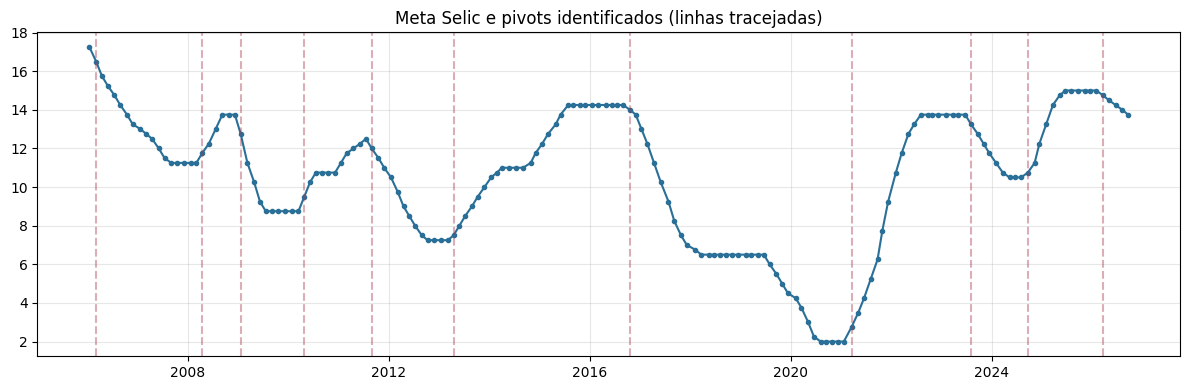

In [6]:
cal_regime = calendario_copom.sort_values("data_reuniao").copy()
cal_regime["delta_meta"] = cal_regime["meta_selic"].diff()
cal_regime["direcao"] = np.sign(cal_regime["delta_meta"]).fillna(0).astype(int)

# direcao vigente = ultima direcao NAO NULA (manutencao continua o ciclo anterior)
cal_regime["direcao_copom"] = cal_regime["direcao"].replace(0, np.nan).ffill().fillna(0).astype(int)
cal_regime["flag_pivot_copom"] = (
    (cal_regime["direcao_copom"] != cal_regime["direcao_copom"].shift(1))
    & cal_regime["direcao_copom"].shift(1).notna()
    & (cal_regime["direcao_copom"] != 0)
)

cal_regime["grupo_ciclo"] = cal_regime["flag_pivot_copom"].cumsum()
cal_regime["bps_acumulado_ciclo"] = (
    cal_regime.groupby("grupo_ciclo")["delta_meta"].cumsum().fillna(0) * 100
)
inicio_ciclo = cal_regime.groupby("grupo_ciclo")["data_reuniao"].transform("min")
cal_regime["meses_desde_pivot"] = ((cal_regime["data_reuniao"] - inicio_ciclo).dt.days / 30.4375).round(1)
cal_regime["fase_ciclo"] = cal_regime["direcao_copom"].map(
    {1: "aperto", -1: "afrouxamento", 0: "manutencao"}
)

regime = cal_regime.rename(columns={"meta_selic": "ultima_meta_selic_conhecida"})[[
    "data_reuniao", "ultima_meta_selic_conhecida", "direcao_copom", "flag_pivot_copom",
    "meses_desde_pivot", "fase_ciclo", "bps_acumulado_ciclo",
]]
regime = calcular_data_disponibilidade(regime, "data_reuniao", "meta_selic")

COLUNAS_REGIME = ["ultima_meta_selic_conhecida", "direcao_copom", "flag_pivot_copom",
                  "meses_desde_pivot", "fase_ciclo", "bps_acumulado_ciclo"]

for nome in paineis:
    paineis[nome] = juntar_as_of(paineis[nome], "data_travamento", regime,
                                 COLUNAS_REGIME, prefixo="regime")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cal_regime["data_reuniao"], cal_regime["meta_selic"], color="#2a6f97", marker="o", markersize=3)
for _, row in cal_regime.loc[cal_regime["flag_pivot_copom"]].iterrows():
    ax.axvline(row["data_reuniao"], color="#a63446", alpha=0.4, linestyle="--")
ax.set_title("Meta Selic e pivots identificados (linhas tracejadas)")
plt.tight_layout()
plt.show()

## 6. Momento macro e mercado

Todas as features macro são **compartilhadas entre os painéis** — descrevem o estado da economia na `data_travamento`, não o indicador sendo previsto. Cada série mensal do SGS chega indexada pelo **primeiro dia** do mês de referência, então ajustamos para fim de mês antes de aplicar a regra de defasagem.

In [7]:
def preparar_mensal(serie, nome_regra):
    s = serie.copy()
    s["fim_periodo"] = s["data"] + pd.offsets.MonthEnd(0)
    return calcular_data_disponibilidade(s, "fim_periodo", nome_regra).sort_values("data")


# --- IPCA: momento, aceleracao e acumulado 12m ----------------------------
ipca_prep = preparar_mensal(sgs_ipca_mensal, "ipca_mensal")
ipca_prep["momento_ipca_3m"] = ipca_prep["valor"].rolling(3).mean()
ipca_prep["momento_ipca_6m"] = ipca_prep["valor"].rolling(6).mean()
ipca_prep["aceleracao_ipca"] = ipca_prep["momento_ipca_3m"] - ipca_prep["momento_ipca_6m"]
ipca_prep["ipca_12m"] = ((1 + ipca_prep["valor"] / 100).rolling(12).apply(np.prod, raw=True) - 1) * 100

meta_prep = calcular_data_disponibilidade(sgs_meta_inflacao, "data", "meta_inflacao")

# --- Selic diaria, IBC-Br, IC-Br: variacao em janelas ---------------------
def preparar_momento(serie, nome_regra, prefixo, e_diaria):
    s = serie.copy()
    if e_diaria:
        s = calcular_data_disponibilidade(s, "data", nome_regra)
    else:
        s["fim_periodo"] = s["data"] + pd.offsets.MonthEnd(0)
        s = calcular_data_disponibilidade(s, "fim_periodo", nome_regra)
    s = s.sort_values("data")
    passo = 1 if e_diaria else 30.4375
    for rot, dias in [("3m", 91), ("6m", 182)]:
        s[f"momento_{prefixo}_{rot}"] = s["valor"] - s["valor"].shift(int(round(dias / passo)))
    s[f"nivel_{prefixo}"] = s["valor"]
    return s


selic_prep = preparar_momento(sgs_meta_selic, "meta_selic", "selic", e_diaria=True)
ibcbr_prep = preparar_momento(sgs_ibcbr, "ibcbr", "ibcbr", e_diaria=False)
icbr_prep = preparar_momento(sgs_icbr, "icbr", "icbr", e_diaria=False)


def preparar_mercado(serie, nome_regra):
    s = serie.sort_values("data").copy()
    s["retorno_1m"] = s["fechamento"].pct_change(21) * 100
    s["retorno_3m"] = s["fechamento"].pct_change(63) * 100
    s["vol_21d"] = s["fechamento"].pct_change().rolling(21).std() * np.sqrt(21) * 100
    s["nivel"] = s["fechamento"]
    return calcular_data_disponibilidade(s, "data", nome_regra)


usdbrl_prep = preparar_mercado(mercado_usdbrl, "usdbrl")
tnx_prep = preparar_mercado(mercado_tnx, "tnx")

for nome in paineis:
    p = paineis[nome]
    p = juntar_as_of(p, "data_travamento", ipca_prep,
                     ["momento_ipca_3m", "momento_ipca_6m", "aceleracao_ipca", "ipca_12m"],
                     prefixo="macro")
    p = juntar_as_of(p, "data_travamento", meta_prep, ["valor"], prefixo="meta_infl")
    p = p.rename(columns={"meta_infl_valor": "meta_inflacao_vigente"})
    p["hiato_ipca_meta"] = p["macro_ipca_12m"] - p["meta_inflacao_vigente"]

    p = juntar_as_of(p, "data_travamento", selic_prep,
                     ["nivel_selic", "momento_selic_3m", "momento_selic_6m"], prefixo="mmselic")
    p = juntar_as_of(p, "data_travamento", ibcbr_prep,
                     ["momento_ibcbr_3m", "momento_ibcbr_6m"], prefixo="mmibcbr")
    p = juntar_as_of(p, "data_travamento", icbr_prep,
                     ["momento_icbr_3m", "momento_icbr_6m"], prefixo="mmicbr")
    # Simplificacao documentada: usamos IPCA 12m REALIZADO como proxy da
    # inflacao esperada (o endpoint de expectativa 12m suavizada nao foi
    # coletado). E um juro real ex-POST, nao ex-ante estrito.
    p["juro_real_ex_ante"] = p["mmselic_nivel_selic"] - p["macro_ipca_12m"]

    p = juntar_as_of(p, "data_travamento", usdbrl_prep,
                     ["retorno_1m", "retorno_3m", "vol_21d"], prefixo="usdbrl")
    p = juntar_as_of(p, "data_travamento", tnx_prep,
                     ["nivel", "retorno_1m", "retorno_3m"], prefixo="tnx")
    paineis[nome] = p.rename(columns={
        "tnx_nivel": "nivel_tnx", "tnx_retorno_1m": "variacao_tnx_1m",
        "tnx_retorno_3m": "variacao_tnx_3m",
    })

print("Features macro e de mercado unidas aos", len(paineis), "paineis.")
paineis["ipca"][["macro_momento_ipca_3m", "hiato_ipca_meta", "mmselic_nivel_selic",
                 "usdbrl_retorno_3m", "nivel_tnx"]].describe().round(3)

Features macro e de mercado unidas aos 5 paineis.


,macro_momento_ipca_3m,hiato_ipca_meta,mmselic_nivel_selic,usdbrl_retorno_3m,nivel_tnx
count,970.000,970.000,970.000,970.000,970.000
mean,0.451,1.414,10.466,0.801,2.896
std,0.270,2.190,3.486,8.632,1.130
min,-0.443,-2.123,2.000,-31.106,0.536
25%,0.260,-0.015,8.000,-4.032,2.000
50%,0.417,1.264,11.250,-0.521,2.741
75%,0.633,2.138,13.250,5.085,3.879
max,1.260,8.631,17.250,36.579,5.138


## 7. Validação final do controle de look-ahead

`juntar_as_of` já valida a cada chamada (e levantaria exceção antes de chegarmos aqui). Esta célula é a rede de segurança final sobre os painéis consolidados, agora com as defasagens novas de IGP-M (divulgado **dentro** do mês de referência), Câmbio e PNADC (~60 dias).

In [8]:
total_validado = 0
for nome, p in paineis.items():
    colunas_disp = [c for c in p.columns if c.endswith("_data_disponibilidade")]
    for col in colunas_disp:
        violacoes = (p[col] > p["data_travamento"]).fillna(False)
        assert not violacoes.any(), f"{nome}.{col}: {violacoes.sum()} violacao(oes) de look-ahead!"
    total_validado += len(p)
    print(f"{nome:<12} OK | {len(colunas_disp)} colunas de disponibilidade | {len(p):>4} linhas")

print()
print(f"OK: nenhum vazamento em {total_validado:,} linhas nos {len(paineis)} paineis.")

ipca         OK | 8 colunas de disponibilidade |  970 linhas
cambio       OK | 8 colunas de disponibilidade |  970 linhas
igpm         OK | 8 colunas de disponibilidade |  970 linhas
desocupacao  OK | 8 colunas de disponibilidade |  214 linhas
selic        OK | 8 colunas de disponibilidade |  648 linhas

OK: nenhum vazamento em 3,772 linhas nos 5 paineis.


## 8. Persistência e panorama

In [9]:
for nome, p in paineis.items():
    final = p.drop(columns=[c for c in p.columns if c.endswith("_data_disponibilidade")])
    salvar_dataset(final, DIR_PROCESSADO, f"painel_{nome}",
                   fonte="derivado (Etapa 2)", coluna_data="data_travamento")
    print(f"painel_{nome:<12} {final.shape[0]:>4} linhas x {final.shape[1]} colunas")

painel_ipca          970 linhas x 45 colunas


painel_cambio        970 linhas x 45 colunas


painel_igpm          970 linhas x 45 colunas


painel_desocupacao   214 linhas x 45 colunas


painel_selic         648 linhas x 47 colunas


### Panorama: o Focus bate o benchmark ingênuo?

A régua mínima de qualquer projeção profissional é bater "não prever mudança". Mas o benchmark ingênuo **precisa respeitar o mesmo conjunto de informação do analista**: usar o último valor **já publicado** na `data_travamento`, e não `realizado(P−h)`.

Isso importa de verdade. Em uma primeira versão deste notebook, o benchmark usava `realizado(P−h)`, e a Taxa de desocupação aparecia com razão 2,19 em `h=1` — Focus "péssimo". Era artefato: a PNADC sai com ~60 dias de defasagem, então o analista **não tinha** o valor do mês anterior. Respeitando a defasagem, a razão cai para 0,79. Da mesma forma, normalizar o erro pelo desvio-padrão do *nível* da série (em vez da variação) fazia o Câmbio parecer o melhor indicador — o oposto da verdade conhecida.

`razão = MAE_Focus / MAE_ingênuo`. Abaixo de 1, o Focus agrega valor; acima de 1, perde para não prever mudança.

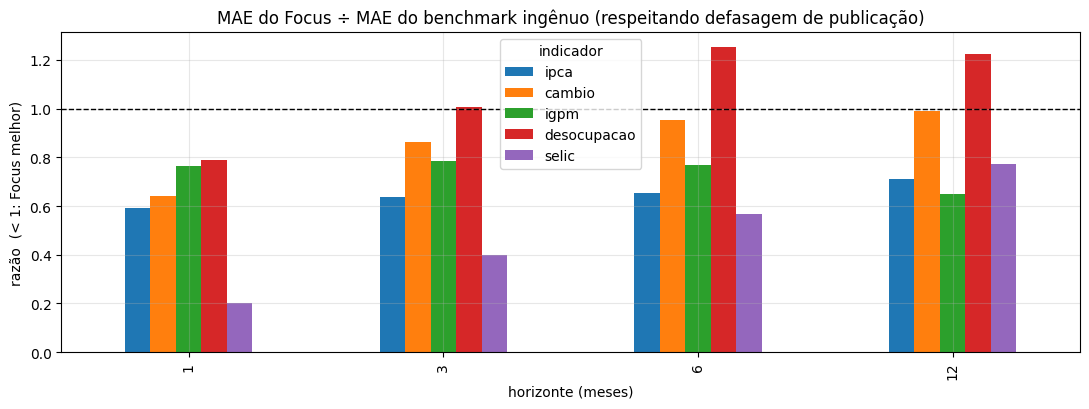

indicador,ipca,cambio,igpm,desocupacao,selic
horizonte,,,,,
1,0.59,0.64,0.77,0.79,0.20
3,0.64,0.86,0.79,1.01,0.40
6,0.65,0.95,0.77,1.25,0.57
12,0.71,0.99,0.65,1.23,0.77


In [10]:
linhas = []
for indicador, cfg in INDICADORES_MENSAIS.items():
    nome = cfg["nome"]
    for h in HORIZONTES_MESES:
        sub = paineis[nome].loc[paineis[nome]["horizonte"] == h]
        ingenua = previsao_ingenua_mensal(sub, realizados[nome], cfg["regra"])
        linhas.append({
            "indicador": nome, "horizonte": h,
            "MAE_focus": sub["erro_focus"].abs().mean(),
            "MAE_ingenuo": (sub["realizado"] - ingenua).abs().mean(),
        })

for h in HORIZONTES_MESES:
    sub = paineis["selic"].loc[paineis["selic"]["horizonte"] == h]
    linhas.append({
        "indicador": "selic", "horizonte": h,
        "MAE_focus": sub["erro_focus"].abs().mean(),
        "MAE_ingenuo": (sub["realizado"] - previsao_ingenua_selic(sub)).abs().mean(),
    })

bench = pd.DataFrame(linhas)
bench["razao"] = bench["MAE_focus"] / bench["MAE_ingenuo"]
razao = bench.pivot(index="horizonte", columns="indicador", values="razao")[
    ["ipca", "cambio", "igpm", "desocupacao", "selic"]
]

fig, ax = plt.subplots(figsize=(11, 4.2))
razao.plot(kind="bar", ax=ax)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_title("MAE do Focus ÷ MAE do benchmark ingênuo (respeitando defasagem de publicação)")
ax.set_ylabel("razão  (< 1: Focus melhor)")
ax.set_xlabel("horizonte (meses)")
plt.tight_layout()
plt.show()

display(razao.round(2))

**Leituras:** o Câmbio em `h=12` fica em ~0,99 — indistinguível do passeio aleatório, a confirmação clássica de Meese-Rogoff. Já a Taxa de desocupação em `h=12` é o único caso em que o Focus perde de verdade (~1,23), mas a amostra dela cobre só **2021-10 em diante** (214 linhas), dominada pela queda pós-COVID — indício, não conclusão.

### Próximo passo

A **Etapa 3** (`03_eda.ipynb`) avalia a qualidade desses cinco painéis — perfil de erro por horizonte e regime, Mincer-Zarnowitz, autocorrelação — e acrescenta o teste central desta reformulação: **a dispersão que o Focus publica é uma medida honesta da própria incerteza?**